# NMC5342 — TikTok Finance Comments
**Student ID:** `A0352776R`

**Project context:** Social media comments on a finance-related TikTok account
## Parts 1–4: an annotated, reproducible analysis
**Case:** comments on @dr.jubairsfinance in the public Bright Data / luminati-io sample.
**Unit:** one comment, not one video or one person.

### Research questions
1. What topics are discussed in this finance creator's comment section?
2. What sentiment does the comment text express?
3. How does excluding suspected investment-promotion comments change estimated sentiment and topics?

### Design and interpretation
- The account is selected before modelling. Keep raw data and comment IDs; repeated wording is not automatically a duplicate record.
- Promotion flags are reproducible heuristics, not verified fraud/bot labels. Compare the same eligible corpus before/after flag-based exclusion.
- TextBlob sentiment measures lexical tone, not trust, factual accuracy, investment quality, or attitude toward a known target.
- LDA topics are exploratory patterns in short comments. Fixed-model topic shares and refitted models answer different questions.
- This convenience sample cannot represent all TikTok users or establish causality.

**Source:** https://github.com/luminati-io/Social-media-dataset-samples/blob/main/TikTok-datasets.csv


# NMC5342 Individual Assignment — Part 1: Python Refresher and Setup

**Objective:** Demonstrate basic Python programming logic, including loops, conditional statements, functions, and simple text manipulation.

## 1. Python environment setup

In [48]:
# Import Python's standard libraries for version information and text matching.
import sys
import re

# Confirm that the notebook is running with Python 3.
print("Python version:", sys.version.split()[0])

Python version: 3.13.18


## 2. Loop and control flow



In [49]:
# Create a list of short example sentences.
sentences = [
     "I love 5342.",
    "This is my favourite class.",
      "I am learning PYTHON."
]

# Process each sentence in the list using a for loop.
for sentence in sentences:
    print("Sentence:", sentence)  # Display the original sentence.

    # Split the sentence at whitespace, then count the resulting words.
    word_count = len(sentence.split())
    print("Word count:", word_count)

    # Convert to lowercase to perform a case-insensitive keyword check.
    if "python" in sentence.lower():
        print("Contains the word 'Python': Yes")
    else:
        print("Contains the word 'Python': No")

    print("-" * 40)  # Separate each sentence's output for readability.

Sentence: I love 5342.
Word count: 3
Contains the word 'Python': No
----------------------------------------
Sentence: This is my favourite class.
Word count: 5
Contains the word 'Python': No
----------------------------------------
Sentence: I am learning PYTHON.
Word count: 4
Contains the word 'Python': Yes
----------------------------------------


## 3. Function: extract hashtags and mentions

The function below takes one string and returns a list of elements starting with `#` (hashtags) or `@` (mentions), in the order they appear.

In [50]:
# Define a reusable function that extracts hashtags and user mentions.
def extract_entities(text):
    # Match hashtags (#...) and mentions (@...) followed by word characters.
    entities = re.findall(r"#\w+|@\w+", text)
    return entities  # Return the matched items as a Python list.

# Try the function using illustrative social media comments.
example_1 = "I follow #Finance and @MarketNews for daily updates!"
example_2 = "Join @TradingGroup to discuss #Stocks and #Investing."

print("Example 1:", extract_entities(example_1))
print("Example 2:", extract_entities(example_2))

Example 1: ['#Finance', '@MarketNews']
Example 2: ['@TradingGroup', '#Stocks', '#Investing']


## 4. Quick verification

These checks confirm that the extraction function returns the expected list and handles text without hashtags or mentions.

In [51]:
# Check the expected results. An assertion raises an error if a result is wrong.
assert extract_entities("I love #AI and @OpenSource!") == ["#AI", "@OpenSource"]
assert extract_entities("No hashtags or mentions here.") == []

print("All Part 1 function checks passed.")

All Part 1 function checks passed.


## Part 1 conclusion

This notebook demonstrates the required Python fundamentals: using a list and `for` loop to process sentences, using `.split()` for basic word counts, applying a case-insensitive `if`/`else` condition, and defining a function to extract social media hashtags and mentions. These skills will support later text preprocessing and analysis in Parts 2–4.

**Next step:** Import and inspect the actual social media dataset in Part 2

In [52]:
#@title Parts 2–4 — Analysis environment and reproducibility
%pip -q install "gensim>=4.4,<5" "textblob>=0.19,<1" "langdetect==1.0.9" wordcloud

import re, io, json, hashlib, sys, platform, warnings
from pathlib import Path
from collections import Counter
from importlib.metadata import version
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from textblob import TextBlob
from langdetect import detect_langs, DetectorFactory
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from wordcloud import WordCloud
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)
DetectorFactory.seed = SEED
OUT = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'nmc5342_outputs'
OUT.mkdir(exist_ok=True)
for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(resource, quiet=True)
pd.set_option('display.max_colwidth', 160)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
packages = ['pandas','numpy','nltk','textblob','gensim','scipy','scikit-learn','langdetect','wordcloud']
versions = {p: version(p) for p in packages}
print('Python:', platform.python_version(), '| Seed:', SEED)
display(pd.Series(versions, name='installed_version').to_frame())
(OUT / 'environment.json').write_text(json.dumps({'python':platform.python_version(), 'packages':versions, 'seed':SEED}, indent=2))
print('Environment ready. Outputs will be written to', OUT)


Python: 3.13.18 | Seed: 42


,installed_version
pandas,2.2.3
numpy,2.4.6
nltk,3.9.1
textblob,0.19.0
gensim,4.4.0
scipy,1.16.3
scikit-learn,1.6.1
langdetect,1.0.9
wordcloud,1.9.6


Environment ready. Outputs will be written to /content/nmc5342_outputs


In [53]:
# Part 2 — Data Familiarization and Preparation
import pandas as pd

# 1. Load the CSV
SOURCE = "https://raw.githubusercontent.com/luminati-io/Social-media-dataset-samples/main/TikTok-datasets.csv"

# Keep long IDs as strings to preserve their original values.
raw = pd.read_csv(SOURCE, dtype=str)
print("Rows and columns:", raw.shape)


# 2. Inspect the dataset
display(raw.head())
raw.info()
display(raw.describe(include="all"))


# 3. Identify the key columns
# commenter_id: comment user's ID
# date_created: comment date and time
# comment_text: comment content
# num_likes: likes received by the comment
# num_replies: replies received by the comment
# post_id: video ID

key_columns = [
    "commenter_id",
    "date_created",
    "comment_text",
    "num_likes",
    "num_replies"
]
display(raw[key_columns].head())


# 4. Check missing values and duplicates
print("Missing values by column:")
print(raw.isnull().sum())

print("Fully duplicated rows:", raw.duplicated().sum())
print("Repeated comment IDs:", raw["comment_id"].duplicated().sum())


# 5. Select the finance account and generate summaries
# Keep comments on @dr.jubairsfinance's videos.
mask = raw["post_url"].str.contains(
    "tiktok.com/@dr.jubairsfinance/",
    regex=False,
    na=False
)
case = raw[mask].copy()

# Remove repeated comment IDs; keep distinct comments with identical wording.
case = case.drop_duplicates("comment_id").reset_index(drop=True)

# Prepare text, dates and numbers for the following parts.
case["raw_text"] = case["comment_text"].fillna("")

case["date_created"] = pd.to_datetime(
    case["date_created"].str.strip('"'),
    utc=True,
    errors="coerce"
)
case["post_date_created"] = pd.to_datetime(
    case["post_date_created"].str.strip('"'),
    utc=True,
    errors="coerce"
)
case["num_likes"] = pd.to_numeric(case["num_likes"], errors="coerce")
case["num_replies"] = pd.to_numeric(case["num_replies"], errors="coerce")

# Give users anonymous labels such as U001 for tables and later exports.
user_ids = sorted(case["commenter_id"].dropna().unique())
user_map = {}

for number, user_id in enumerate(user_ids, start=1):
    user_map[user_id] = f"U{number:03d}"

case["user_label"] = case["commenter_id"].map(user_map)

print("Number of comments:", len(case))
print("Number of videos:", case["post_id"].nunique())
print("Number of comment users:", case["commenter_id"].nunique())
print("First comment (UTC):", case["date_created"].min())
print("Last comment (UTC):", case["date_created"].max())

# Show numerical summaries after converting likes and replies.
display(case[["num_likes", "num_replies"]].describe())

print("Top 5 most active users in the sample (anonymous labels):")
display(case["user_label"].value_counts().head(5))


# 6. Write five sentences summarizing the observations
print("\nInitial observations:")

print(
    f"The public dataset contains {len(raw)} comments "
    f"and {len(raw.columns)} columns."
)

print(
    f"The selected finance account contributes {len(case)} comments "
    f"from {case['post_id'].nunique()} videos and "
    f"{case['commenter_id'].nunique()} comment users, "
    f"covering {case['date_created'].min().date()} to "
    f"{case['date_created'].max().date()} (UTC)."
)

print(
    f"The original dataset contains {raw.isnull().sum().sum()} "
    f"missing entries, {raw.duplicated().sum()} fully duplicated rows "
    f"and {raw['comment_id'].duplicated().sum()} repeated comment IDs."
)

print(
    f"The account sample contains {case['raw_text'].duplicated().sum()} "
    "additional occurrences of identical comment text, which should "
    "not automatically be treated as duplicate records."
)

print(
    "Dates and engagement counts require type conversion, while "
    "language differences, URLs and suspected promotional wording "
    "need further handling in Part 3; this public sample does not "
    "represent all comments on the account."
)

Rows and columns: (1000, 13)


,url,post_url,post_id,post_date_created,date_created,comment_text,num_likes,num_replies,commenter_user_name,commenter_id,commenter_url,comment_id,comment_url
0,https://www.tiktok.com/@dr.jubairsfinance/video/7381541963469786401,https://www.tiktok.com/@dr.jubairsfinance/video/7381541963469786401,7381541963469786401,"""2024-06-17T18:32:51.000Z""","""2024-06-17T20:00:29.000Z""",What is the dividend yield on this fund ?,1,1,fin███ Ai███n,6775842202897449989,https://www.tiktok.com/@finlayaitken6,7381564492096340768,https://www.tiktok.com/@dr.jubairsfinance/video/7381541963469786401?comment_id=7381564492096340768
1,https://www.tiktok.com/@dr.jubairsfinance/video/7411581429219364128,https://www.tiktok.com/@dr.jubairsfinance/video/7411581429219364128,7411581429219364128,"""2024-09-06T17:21:28.000Z""","""2024-09-08T10:21:17.000Z""",Too much stress with stocks bro,2,2,kap███ate███19,6825119749132076038,https://www.tiktok.com/@kapilpatel8819,7412215320918655777,https://www.tiktok.com/@dr.jubairsfinance/video/7411581429219364128?comment_id=7412215320918655777
2,https://www.tiktok.com/@dr.jubairsfinance/video/7411581429219364128,https://www.tiktok.com/@dr.jubairsfinance/video/7411581429219364128,7411581429219364128,"""2024-09-06T17:21:28.000Z""","""2024-09-08T08:52:47.000Z""","wouldn't really call it a crash , maybe use the term ""falling "" crash would be like double digit % decline within 48 hours , unless you just using buzz word...",0,2,Narz,6935516928958579718,https://www.tiktok.com/@narzx97,7412192541975790369,https://www.tiktok.com/@dr.jubairsfinance/video/7411581429219364128?comment_id=7412192541975790369
3,https://www.tiktok.com/@dr.jubairsfinance/video/7438649135953235232,https://www.tiktok.com/@dr.jubairsfinance/video/7438649135953235232,7438649135953235232,"""2024-11-18T15:57:56.000Z""","""2024-11-18T16:09:45.000Z""",Delivery hero.. wish I’d put kkkk in that 🤣,1,1,tra███e13███,7056415277432570885,https://www.tiktok.com/@trazeie13,7438652110797849376,https://www.tiktok.com/@dr.jubairsfinance/video/7438649135953235232?comment_id=7438652110797849376
4,https://www.tiktok.com/@dr.jubairsfinance/video/7400399808696962337,https://www.tiktok.com/@dr.jubairsfinance/video/7400399808696962337,7400399808696962337,"""2024-08-07T14:10:55.000Z""","""2024-08-07T15:55:35.000Z""","I made $82,000 in 7 days investing in trading @PAULWHEELERFX start your investment to make a change",0,0,kar███,7389531293161735174,https://www.tiktok.com/@karenj654,7400426764684264198,https://www.tiktok.com/@dr.jubairsfinance/video/7400399808696962337?comment_id=7400426764684264198


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   url                  1000 non-null   object
 1   post_url             1000 non-null   object
 2   post_id              1000 non-null   object
 3   post_date_created    1000 non-null   object
 4   date_created         1000 non-null   object
 5   comment_text         1000 non-null   object
 6   num_likes            1000 non-null   object
 7   num_replies          1000 non-null   object
 8   commenter_user_name  1000 non-null   object
 9   commenter_id         1000 non-null   object
 10  commenter_url        1000 non-null   object
 11  comment_id           1000 non-null   object
 12  comment_url          1000 non-null   object
dtypes: object(13)
memory usage: 101.7+ KB


,url,post_url,post_id,post_date_created,date_created,comment_text,num_likes,num_replies,commenter_user_name,commenter_id,commenter_url,comment_id,comment_url
count,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,262,262,262,262,999,945,19,16,661,673,673,1000,1000
top,https://www.tiktok.com/@thaiwinnerdotcom/video/7333418632220921089,https://www.tiktok.com/@thaiwinnerdotcom/video/7333418632220921089,7333418632220921089,"""2024-02-10T05:00:00.000Z""","""2024-09-30T21:36:19.000Z""",😁,0,0,pix███nov███nam███,7427807705911673862,https://www.tiktok.com/@pixel_nova7,7381564492096340768,https://www.tiktok.com/@dr.jubairsfinance/video/7381541963469786401?comment_id=7381564492096340768
freq,124,124,124,124,2,14,416,431,28,28,28,1,1


,commenter_id,date_created,comment_text,num_likes,num_replies
0,6775842202897449989,"""2024-06-17T20:00:29.000Z""",What is the dividend yield on this fund ?,1,1
1,6825119749132076038,"""2024-09-08T10:21:17.000Z""",Too much stress with stocks bro,2,2
2,6935516928958579718,"""2024-09-08T08:52:47.000Z""","wouldn't really call it a crash , maybe use the term ""falling "" crash would be like double digit % decline within 48 hours , unless you just using buzz word...",0,2
3,7056415277432570885,"""2024-11-18T16:09:45.000Z""",Delivery hero.. wish I’d put kkkk in that 🤣,1,1
4,7389531293161735174,"""2024-08-07T15:55:35.000Z""","I made $82,000 in 7 days investing in trading @PAULWHEELERFX start your investment to make a change",0,0


Missing values by column:
url                    0
post_url               0
post_id                0
post_date_created      0
date_created           0
comment_text           0
num_likes              0
num_replies            0
commenter_user_name    0
commenter_id           0
commenter_url          0
comment_id             0
comment_url            0
dtype: int64
Fully duplicated rows: 0
Repeated comment IDs: 0
Number of comments: 799
Number of videos: 258
Number of comment users: 499
First comment (UTC): 2024-05-21 16:41:25+00:00
Last comment (UTC): 2024-12-11 23:17:15+00:00


,num_likes,num_replies
count,799.000000,799.000000
mean,1.252816,1.738423
std,2.027669,2.159182
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,1.000000
75%,2.000000,3.000000
max,32.000000,21.000000


Top 5 most active users in the sample (anonymous labels):


,count
user_label,
U145,21
U046,19
U248,16
U032,12
U307,10



Initial observations:
The public dataset contains 1000 comments and 13 columns.
The selected finance account contributes 799 comments from 258 videos and 499 comment users, covering 2024-05-21 to 2024-12-11 (UTC).
The original dataset contains 0 missing entries, 0 fully duplicated rows and 0 repeated comment IDs.
The account sample contains 32 additional occurrences of identical comment text, which should not automatically be treated as duplicate records.
Dates and engagement counts require type conversion, while language differences, URLs and suspected promotional wording need further handling in Part 3; this public sample does not represent all comments on the account.


In [54]:
#@title Part 3A — Language screening and separate text representations
# Sentiment keeps negation/punctuation. Topic tokens are lowercased and lemmatized.
def redact_handles(text):
    return re.sub(r'@[\w.]+', '@USER', str(text))

def lightly_clean(text):
    text = str(text).replace('’', "'").replace('‘', "'")
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'@[\w.]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def language_screen(text):
    candidate = lightly_clean(text)
    if not re.search(r'[A-Za-z]', candidate):
        return ('no_latin_text', 0.0)
    try:
        result = detect_langs(candidate)[0]
        return (result.lang, result.prob)
    except Exception:
        return ('undetermined', 0.0)

case['sentiment_text'] = case.raw_text.map(lightly_clean)
case[['language','language_confidence']] = pd.DataFrame(case.raw_text.map(language_screen).tolist(), index=case.index)
case['eligible_english'] = case.language.eq('en') & case.language_confidence.ge(0.80)
case['display_text'] = case.raw_text.map(redact_handles)
display(case.groupby('language').agg(comments=('comment_id','size')).sort_values('comments',ascending=False))
display(case.loc[~case.eligible_english, ['comment_id','display_text','language','language_confidence']].head(20))

STOP = set(stopwords.words('english')) | {'im','ive','dont','doesnt','cant','youre','thats','u','ur','amp','rt'}
# Retain finance words (e.g. money, trading, profit); removing them would hide RQ3.
lemmatizer = WordNetLemmatizer()
def topic_tokens(text):
    text = lightly_clean(text).lower()
    text = re.sub(r"n['’]t\b", ' not', text)
    words = word_tokenize(text)
    return [lemmatizer.lemmatize(w) for w in words
            if re.fullmatch(r'[a-z]{2,}', w) and w not in STOP]

case['tokens'] = case.raw_text.map(topic_tokens)
case['token_count'] = case.tokens.str.len()
analysis = case.loc[case.eligible_english & case.sentiment_text.str.contains(r'[A-Za-z]', regex=True)].copy()
assert len(analysis) > 20, 'Too few eligible English comments; revisit language screening.'
flow = pd.DataFrame({'stage':['Downloaded comments','Selected account; unique IDs','English (top language en, probability >= .80)','English with >= 3 topic tokens'],
                     'n':[len(raw),len(case),len(analysis),int(analysis.token_count.ge(3).sum())]})
display(flow)
display(analysis[['display_text','sentiment_text','tokens']].head(5))
flow.to_csv(OUT/'sample_flow.csv',index=False)
case[['comment_id','display_text','language','language_confidence','eligible_english']].to_csv(OUT/'language_audit.csv',index=False)
display(Markdown('**Cleaning decisions.** Emoji-only and low-confidence/non-English comments are excluded from English lexical analysis, not called neutral. Language-model probabilities are screening scores, not calibrated certainty. The excluded-text table makes false exclusions visible; short English phrases may be lost. Stopwords and punctuation are removed only for keyword/LDA analysis. Sentiment receives minimally cleaned text to retain negation and punctuation; TextBlob does not reliably capture emoji meaning, sarcasm or finance-specific expressions.'))


,comments
language,
en,701
no_latin_text,14
fr,8
so,8
tl,7
de,7
af,4
undetermined,4
cy,4


,comment_id,display_text,language,language_confidence
5,7427610123872355104,Why not vanguard?,af,0.571427
9,7398017589446214406,"@USER MOVINGCYBER ACCOUNT Es muy perfecto\nEs el mejor hasta la fecha,....",es,0.999998
16,7397896053330838304,Wow! Amazing 😂😂,pl,0.857141
33,7421231034589954848,Better to invest it g,en,0.714284
40,7402767682564801286,@USER,no_latin_text,0.000000
54,7421955485031580448,Haram,tr,0.999308
56,7432024930566898465,Wait you can do day trading in Isa ?,id,0.714285
62,7424202060125766433,interest is haraam,nl,0.999995
74,7421240902784418592,And here’s me getting pennies on £300 lol 🙈,af,0.857139
76,7397887649866548001,Boom 💥😊,so,0.857141


,stage,n
0,Downloaded comments,1000
1,Selected account; unique IDs,799
2,"English (top language en, probability >= .80)",678
3,English with >= 3 topic tokens,593


,display_text,sentiment_text,tokens
0,What is the dividend yield on this fund ?,What is the dividend yield on this fund ?,"[dividend, yield, fund]"
1,Too much stress with stocks bro,Too much stress with stocks bro,"[much, stress, stock, bro]"
2,"wouldn't really call it a crash , maybe use the term ""falling "" crash would be like double digit % decline within 48 hours , unless you just using buzz word...","wouldn't really call it a crash , maybe use the term ""falling "" crash would be like double digit % decline within 48 hours , unless you just using buzz word...","[would, really, call, crash, maybe, use, term, falling, crash, would, like, double, digit, decline, within, hour, unless, using, buzz, word, algorithm]"
3,Delivery hero.. wish I’d put kkkk in that 🤣,Delivery hero.. wish I'd put kkkk in that 🤣,"[delivery, hero, wish, put, kkkk]"
4,"I made $82,000 in 7 days investing in trading @USER start your investment to make a change","I made $82,000 in 7 days investing in trading start your investment to make a change","[made, day, investing, trading, start, investment, make, change]"


**Cleaning decisions.** Emoji-only and low-confidence/non-English comments are excluded from English lexical analysis, not called neutral. Language-model probabilities are screening scores, not calibrated certainty. The excluded-text table makes false exclusions visible; short English phrases may be lost. Stopwords and punctuation are removed only for keyword/LDA analysis. Sentiment receives minimally cleaned text to retain negation and punctuation; TextBlob does not reliably capture emoji meaning, sarcasm or finance-specific expressions.

In [55]:
#@title Part 3B — Flag suspected investment promotions (RQ3 design)
def promotion_features(text):
    """Transparent lexical rules: flags indicate suspicion, never verified misconduct."""
    t = str(text).lower()
    mention = bool(re.search(r'@[\w.]+', t))
    investment = bool(re.search(r'\b(?:invest\w*|trad(?:e|er|ers|es|ing)|forex|crypto\w*|bitcoin)\b', t))
    benefit = bool(re.search(r'\b(?:profit\w*|return\w*|earn\w*|made|making|income|gain\w*|withdraw\w*)\b|financial (?:story|life)', t))
    solicitation = bool(re.search(r'\b(?:contact|dm|message|whatsapp|telegram|guidance)\b|reach out|start your investment', t))
    endorsement = bool(re.search(r'\b(?:thank\w*|grateful|recommend\w*|amazing|wonderful|success\w*|changed|impressed)\b', t))
    amount = bool(re.search(r'[$£€]\s*\d|\b\d[\d,]*(?:\.\d+)?\s*(?:k|dollars|pounds|usd)\b', t))
    strict = mention and investment and benefit and (amount or solicitation)
    base = mention and ((investment and (benefit or solicitation or endorsement)) or (amount and benefit) or (benefit and endorsement))
    broad = base or (investment and amount and benefit and (solicitation or endorsement))
    reasons = [name for name,yes in [('mention',mention),('investment',investment),('benefit_claim',benefit),('solicitation',solicitation),('endorsement',endorsement),('money_amount',amount)] if yes]
    return pd.Series({'promo_strict':strict,'suspected_promo':base,'promo_broad':broad,'flag_features':', '.join(reasons)})

features = case.raw_text.apply(promotion_features)
case[features.columns] = features  # Safe if this cell is rerun.
analysis = case.loc[analysis.index].copy()
assert (analysis.promo_strict <= analysis.suspected_promo).all()
assert (analysis.suspected_promo <= analysis.promo_broad).all()
print('Flags in all account comments:', case[['promo_strict','suspected_promo','promo_broad']].sum().to_dict())
print('Flags in eligible English comments:', analysis[['promo_strict','suspected_promo','promo_broad']].sum().to_dict())
# Repeat wording supports inspection but is not a criterion by itself.
print('\nExamples flagged by the base rule:')
for _,r in analysis.loc[analysis.suspected_promo].sample(n=min(10,int(analysis.suspected_promo.sum())),random_state=SEED).iterrows():
    print(r.comment_id, '|', r.display_text, '|', r.flag_features)
print('\nExamples not flagged:')
for _,r in analysis.loc[~analysis.suspected_promo].sample(n=min(10,int((~analysis.suspected_promo).sum())),random_state=SEED).iterrows():
    print(r.comment_id, '|', r.display_text)
# Leave human labels blank: a rule-generated label is not independent validation.
audit = analysis.groupby('suspected_promo',group_keys=False).apply(lambda g:g.sample(min(20,len(g)),random_state=SEED),include_groups=False)
audit['suspected_promo'] = analysis.loc[audit.index,'suspected_promo']
audit = audit[['comment_id','display_text','suspected_promo','flag_features']].copy()
audit['human_label'] = ''
audit['human_note'] = ''
audit.to_csv(OUT/'promotion_audit_for_student.csv',index=False)
display(Markdown('**Operational definition.** The base flag requires a tagged account plus investment/benefit/solicitation or testimonial signals in the combinations shown in the function. Ordinary investment questions and repeated short comments are not automatically flagged. Strict and broad rules provide sensitivity checks. These examples are an inspection aid; no human accuracy, precision, recall or inter-coder agreement is claimed. Unflagged means only “not detected by this rule,” not “verified genuine.”'))


Flags in all account comments: {'promo_strict': 12, 'suspected_promo': 63, 'promo_broad': 63}
Flags in eligible English comments: {'promo_strict': 12, 'suspected_promo': 63, 'promo_broad': 63}

Examples flagged by the base rule:
7420986451502891782 | My $300 turned into $11,500, Interested in crypto trading, but don't know how to trade, and you need trading guidance contact @USER Mariana | mention, investment, solicitation, money_amount
7410073680380166918 | So much joy in my heart, I just received my profit of $6,700. I can now pay up my bills thank you😇 @USER | mention, benefit_claim, endorsement, money_amount
7400426764684264198 | I made $82,000 in 7 days investing in trading @USER start your investment to make a change | mention, investment, benefit_claim, solicitation, money_amount
7420605327585428229 | @USER has paved the way for my successful daily trading and winning. I can't thank him enough for his exceptional services and support. | mention, investment, endorsement
739606133

**Operational definition.** The base flag requires a tagged account plus investment/benefit/solicitation or testimonial signals in the combinations shown in the function. Ordinary investment questions and repeated short comments are not automatically flagged. Strict and broad rules provide sensitivity checks. These examples are an inspection aid; no human accuracy, precision, recall or inter-coder agreement is claimed. Unflagged means only “not detected by this rule,” not “verified genuine.”

Top 20 words, all eligible English comments:
     term  frequency
  trading         80
     year         53
investing         50
      isa         50
    stock         40
    money         39
     good         39
   invest         38
   market         37
     cash         36
     much         35
     best         34
      get         33
     like         32
      day         32
   thanks         32
      put         31
   profit         31
    thank         31
     fund         30

Top 20 words, after base-rule exclusion:
     term  frequency
     year         53
      isa         50
investing         45
  trading         42
    stock         40
    money         38
   invest         38
   market         36
     cash         36
      get         32
     much         31
     fund         30
      put         30
 interest         29
     like         28
      day         28
    would         27
      buy         27
     good         26
      one         26


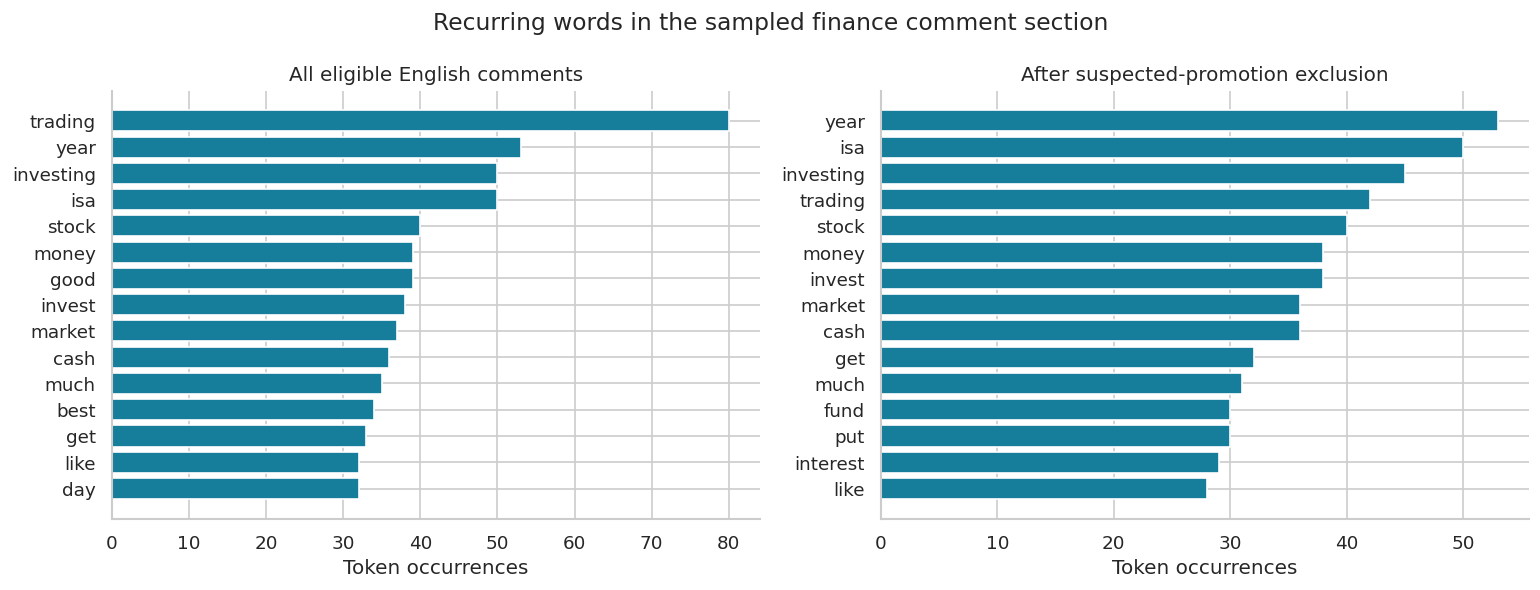

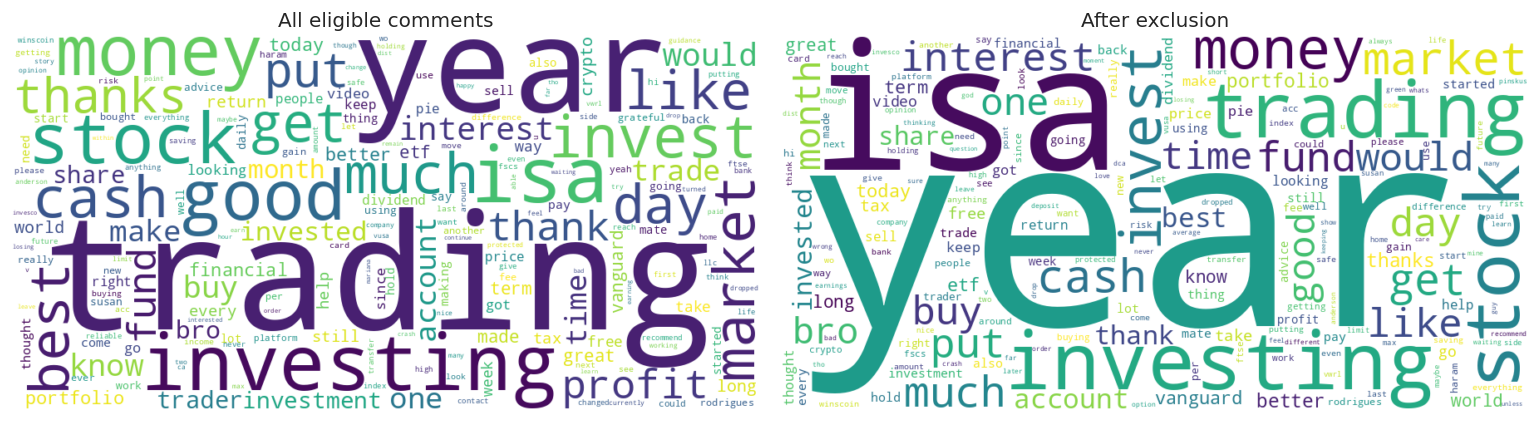


Highest mean TF–IDF terms (baseline):
     term  mean_tfidf_all  mean_tfidf_retained  change
  trading          0.0280               0.0180 -0.0099
investing          0.0226               0.0229  0.0003
      isa          0.0219               0.0242  0.0022
     year          0.0213               0.0235  0.0022
     good          0.0194               0.0154 -0.0040
   market          0.0191               0.0207  0.0016
   invest          0.0187               0.0206  0.0019
    money          0.0181               0.0195  0.0015
   thanks          0.0176               0.0135 -0.0042
     best          0.0175               0.0151 -0.0024
     much          0.0173               0.0174  0.0001
     cash          0.0172               0.0189  0.0018
    thank          0.0170               0.0150 -0.0020
      put          0.0169               0.0181  0.0012
    stock          0.0166               0.0183  0.0017

Largest decreases after exclusion, with fixed IDF:
    term  mean_tfidf_all  mea

**Interpretation：**  **Trading** was the most common word in the 678 English comments, appearing 80 times. Other frequent words included **year** (53), **investing** and **isa** (50 each), and **stock** (40). **Trading**, **investing**, **isa** and **year** also ranked highly in the average TF-IDF scores.

These words suggest that much of the discussion is about investment choices and managing **money**. **Stock**, **market** and **profit** relate to **trading** and investment returns, while **isa**, **cash**, **interest** and **fund** suggest questions about savings, accounts and funds. **Year** may refer to investment periods or past performance, so the comments need to be read in context before deciding what it means.

After excluding comments flagged as possible promotions, **trading** dropped from 80 to 42 occurrences, while **year** and **isa** stayed at 53 and 50. The average TF-IDF scores for **trading** and **profit** also fell. This suggests that promotional wording may help explain why **trading** and returns stand out in the original results, while savings and account-related discussions remain common after exclusion. These counts describe word use rather than the number of people discussing each issue, and the flags do not prove that a comment is fraudulent.

In [56]:
#@title Part 3C — Word frequencies, word cloud and TF–IDF (RQ1)
def word_table(frame):
    counts = Counter(w for tokens in frame.tokens for w in tokens)
    return pd.DataFrame(counts.most_common(),columns=['term','frequency'])

freq_all = word_table(analysis)
freq_retained = word_table(analysis.loc[~analysis.suspected_promo])
print('Top 20 words, all eligible English comments:')
print(freq_all.head(20).to_string(index=False))
print('\nTop 20 words, after base-rule exclusion:')
print(freq_retained.head(20).to_string(index=False))
freq_all.to_csv(OUT/'word_frequency_all.csv',index=False)
freq_retained.to_csv(OUT/'word_frequency_retained.csv',index=False)

fig,axes = plt.subplots(1,2,figsize=(13,5))
for ax,table,title in zip(axes,[freq_all,freq_retained],['All eligible English comments','After suspected-promotion exclusion']):
    top = table.head(15).iloc[::-1]
    ax.barh(top.term,top.frequency,color='#167D9A')
    ax.set_title(title); ax.set_xlabel('Token occurrences')
fig.suptitle('Recurring words in the sampled finance comment section',fontsize=14)
fig.tight_layout(); fig.savefig(OUT/'01_word_frequencies.png',bbox_inches='tight'); plt.show()

fig,axes = plt.subplots(1,2,figsize=(13,4))
for ax,table,title in zip(axes,[freq_all,freq_retained],['All eligible comments','After exclusion']):
    cloud = WordCloud(width=900,height=450,background_color='white',random_state=SEED,
                      colormap='viridis',collocations=False).generate_from_frequencies(dict(zip(table.term,table.frequency)))
    ax.imshow(cloud,interpolation='bilinear'); ax.axis('off'); ax.set_title(title)
fig.tight_layout(); fig.savefig(OUT/'02_wordclouds.png',bbox_inches='tight'); plt.show()

# Fit once on the baseline corpus: same vocabulary and IDF for a fair before/after comparison.
vectorizer = TfidfVectorizer(analyzer=lambda tokens:tokens,min_df=2,max_df=0.90)
X = vectorizer.fit_transform(analysis.tokens)
terms = vectorizer.get_feature_names_out()
keep_mask = (~analysis.suspected_promo).to_numpy()
tfidf = pd.DataFrame({'term':terms,'mean_tfidf_all':np.asarray(X.mean(axis=0)).ravel(),
                      'mean_tfidf_retained':np.asarray(X[keep_mask].mean(axis=0)).ravel()})
tfidf['change'] = tfidf.mean_tfidf_retained-tfidf.mean_tfidf_all
print('\nHighest mean TF–IDF terms (baseline):')
print(tfidf.nlargest(15,'mean_tfidf_all').round(4).to_string(index=False))
print('\nLargest decreases after exclusion, with fixed IDF:')
print(tfidf.nsmallest(10,'change').round(4).to_string(index=False))
tfidf.to_csv(OUT/'tfidf_comparison.csv',index=False)
display(Markdown("""**Interpretation：**  **Trading** was the most common word in the 678 English comments, appearing 80 times. Other frequent words included **year** (53), **investing** and **isa** (50 each), and **stock** (40). **Trading**, **investing**, **isa** and **year** also ranked highly in the average TF-IDF scores.

These words suggest that much of the discussion is about investment choices and managing **money**. **Stock**, **market** and **profit** relate to **trading** and investment returns, while **isa**, **cash**, **interest** and **fund** suggest questions about savings, accounts and funds. **Year** may refer to investment periods or past performance, so the comments need to be read in context before deciding what it means.

After excluding comments flagged as possible promotions, **trading** dropped from 80 to 42 occurrences, while **year** and **isa** stayed at 53 and 50. The average TF-IDF scores for **trading** and **profit** also fell. This suggests that promotional wording may help explain why **trading** and returns stand out in the original results, while savings and account-related discussions remain common after exclusion. These counts describe word use rather than the number of people discussing each issue, and the flags do not prove that a comment is fraudulent."""))


         sample   n  mean_polarity  mean_subjectivity  Negative_pct  Neutral_pct  Positive_pct
   All eligible 678          0.155              0.318         9.587       44.838        45.575
After exclusion 615          0.135              0.309        10.569       47.154        42.276
   Flagged only  63          0.348              0.400         0.000       22.222        77.778
Threshold: negative < -.05; neutral [-.05, .05]; positive > .05.
Neutral is an operational score band, not proof that the writer has no opinion.


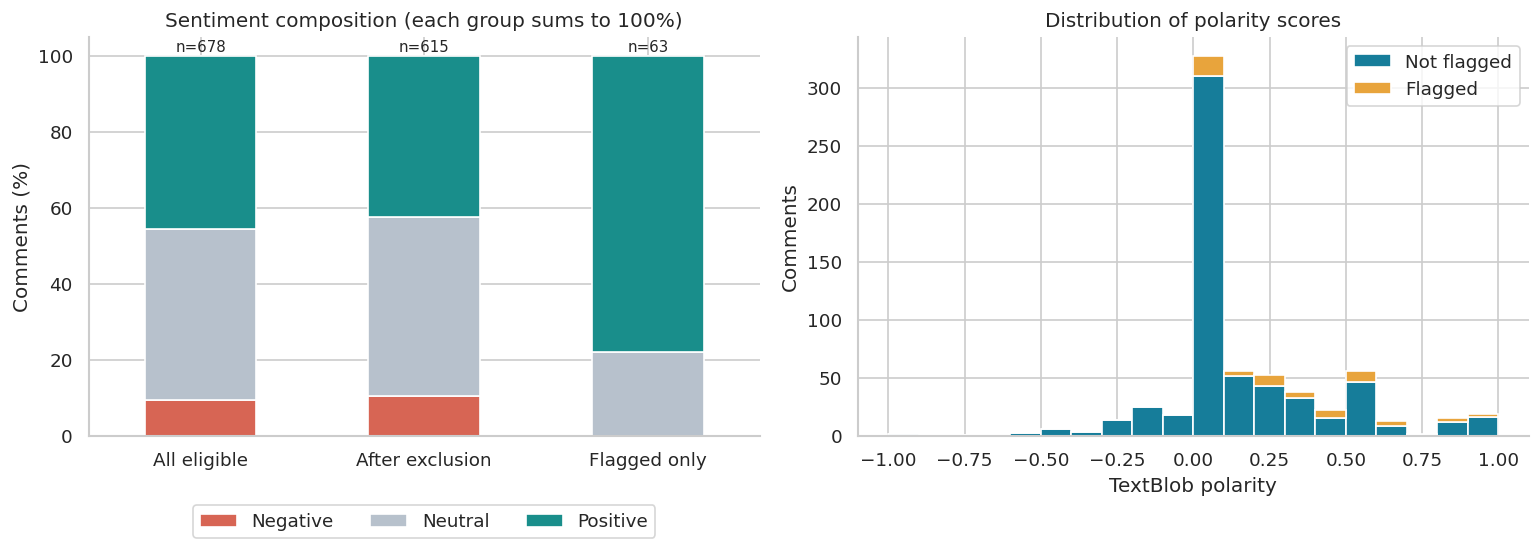


 Negative examples:
-0.400 | flagged=False | There hasn’t been a worse time to invest in the S and P🤣
-0.312 | flagged=False | what does gainign intrest from shares mean do u risk losing shares
-0.200 | flagged=False | Theres no point looking at it everyday

 Neutral examples:
+0.000 | flagged=False | Nvdia should have 🚀 over $200 but those market makers playing games
+0.000 | flagged=False | I bought 15k of the ftse all world yesterday... so it's probably my fault 🤣
+0.000 | flagged=False | Why invest in FTSE 100 over S&P500

 Positive examples:
+0.250 | flagged=False | Can you please explain the holding cash in trading 212 more please. Do you have a current account account with all those banks or do you just drop the funds and it automatically show that?
+0.700 | flagged=False | Keeping 20k in Vanguard at the moment in cash, not as good interest but in a Sipp so don’t want to take it out. Waiting for a market drop, happy with what I have made this year so lowering my risk. £15 a day

**RQ2–RQ3, initial answer.** Excluding 63 base-rule flagged comments changes the positive share from 45.6% to 42.3% (-3.3 percentage points). Mean polarity changes from 0.155 to 0.135. These are descriptive changes in a nested sample, not a randomized effect or evidence of creator trust. Rule-based exclusion partly targets testimonial wording, so a tone difference may partly reflect the rule's construction.

In [57]:
#@title Part 4A — TextBlob polarity, subjectivity and sentiment (RQ2–RQ3)
# TextBlob provides both quantities requested by the assignment; VADER alone does not provide subjectivity.
scores = analysis.sentiment_text.map(lambda t: TextBlob(t).sentiment)
analysis['polarity'] = [s.polarity for s in scores]
analysis['subjectivity'] = [s.subjectivity for s in scores]
def sentiment_label(p, threshold=0.05):
    if p > threshold:
        return 'Positive'
    elif p < -threshold:
        return 'Negative'
    return 'Neutral'
analysis['sentiment'] = analysis.polarity.map(sentiment_label)
ORDER = ['Negative','Neutral','Positive']

def sentiment_summary(frame, name):
    counts = frame.sentiment.value_counts().reindex(ORDER,fill_value=0)
    return {'sample':name,'n':len(frame),'mean_polarity':frame.polarity.mean(),
            'mean_subjectivity':frame.subjectivity.mean(),
            **{label+'_pct':100*counts[label]/len(frame) for label in ORDER}}

retained = analysis.loc[~analysis.suspected_promo].copy()
flagged = analysis.loc[analysis.suspected_promo].copy()
sentiment_results = pd.DataFrame([sentiment_summary(analysis,'All eligible'),sentiment_summary(retained,'After exclusion'),sentiment_summary(flagged,'Flagged only')])
print(sentiment_results.round(3).to_string(index=False))
print('Threshold: negative < -.05; neutral [-.05, .05]; positive > .05.')
print('Neutral is an operational score band, not proof that the writer has no opinion.')
sentiment_results.to_csv(OUT/'sentiment_summary.csv',index=False)

fig,axes = plt.subplots(1,2,figsize=(13,4.8))
plot_data = sentiment_results.set_index('sample')[[s+'_pct' for s in ORDER]]
plot_data.columns = ORDER
plot_data.plot.bar(stacked=True,ax=axes[0],color=['#D76554','#B7C1CC','#198E8B'],rot=0)
axes[0].set_ylabel('Comments (%)'); axes[0].set_xlabel(''); axes[0].set_ylim(0,105)
axes[0].set_title('Sentiment composition (each group sums to 100%)')
axes[0].legend(title='',loc='upper center',bbox_to_anchor=(.5,-.15),ncol=3)
for i,row in sentiment_results.iterrows():
    axes[0].text(i,101,f"n={int(row['n'])}",ha='center',fontsize=9)
axes[1].hist([retained.polarity,flagged.polarity],bins=np.linspace(-1,1,21),label=['Not flagged','Flagged'],color=['#167D9A','#E8A43C'],stacked=True)
axes[1].set_xlabel('TextBlob polarity'); axes[1].set_ylabel('Comments')
axes[1].set_title('Distribution of polarity scores'); axes[1].legend()
fig.tight_layout(); fig.savefig(OUT/'03_sentiment_comparison.png',bbox_inches='tight'); plt.show()

# Inspect polarity in context: words such as “good” need not praise the creator.
for label in ORDER:
    print('\n',label,'examples:')
    subset = analysis.loc[analysis.sentiment.eq(label)]
    for _,r in subset.sample(min(3,len(subset)),random_state=SEED).iterrows():
        print(f'{r.polarity:+.3f} | flagged={r.suspected_promo} | {r.display_text}')
positive_shift = sentiment_results.loc[1,'Positive_pct']-sentiment_results.loc[0,'Positive_pct']
polarity_shift = retained.polarity.mean()-analysis.polarity.mean()
display(Markdown(f'''**RQ2–RQ3, initial answer.** Excluding {len(flagged)} base-rule flagged comments changes the positive share from {sentiment_results.loc[0,'Positive_pct']:.1f}% to {sentiment_results.loc[1,'Positive_pct']:.1f}% ({positive_shift:+.1f} percentage points). Mean polarity changes from {analysis.polarity.mean():.3f} to {retained.polarity.mean():.3f}. These are descriptive changes in a nested sample, not a randomized effect or evidence of creator trust. Rule-based exclusion partly targets testimonial wording, so a tone difference may partly reflect the rule's construction.'''))


In [58]:
#@title Part 4B — Gensim LDA: compare 3, 4 and 5 topics (RQ1)
# LDA consumes word counts, not the TF–IDF matrix.
topic_df = analysis.loc[analysis.token_count.ge(3)].copy()
dictionary = Dictionary(topic_df.tokens.tolist())
dictionary.filter_extremes(no_below=2,no_above=0.90,keep_n=5000)
corpus = [dictionary.doc2bow(tokens) for tokens in topic_df.tokens]
nonempty = np.array([len(bow)>0 for bow in corpus])
topic_df = topic_df.loc[nonempty].copy()
corpus = [bow for bow in corpus if bow]
texts = topic_df.tokens.tolist()
print(f'LDA sample: {len(topic_df)} comments; vocabulary: {len(dictionary)} terms.')
assert len(dictionary) >= 20 and len(topic_df) >= 30

def fit_lda(bows, k, seed=SEED):
    return LdaModel(corpus=bows,id2word=dictionary,num_topics=k,random_state=seed,
                    passes=20,iterations=150,alpha='auto',eta='auto',eval_every=None,
                    minimum_probability=0.0)

models,diagnostics = {},[]
for k in [3,4,5]:
    model = fit_lda(corpus,k)
    models[k] = model
    cv = CoherenceModel(model=model,texts=texts,dictionary=dictionary,coherence='c_v',processes=1).get_coherence()
    tops = [[w for w,_ in model.show_topic(t,topn=10)] for t in range(k)]
    diversity = len(set(w for topic in tops for w in topic))/(k*10)
    diagnostics.append({'k':k,'coherence_cv':cv,'top10_word_diversity':diversity})
    print('\nK =',k)
    for topic in model.print_topics(num_topics=k,num_words=10):
        print(topic)
model_diagnostics = pd.DataFrame(diagnostics)
print('\nModel diagnostics (exploratory, not ground-truth accuracy):')
print(model_diagnostics.round(4).to_string(index=False))
# Reproducible selection: maximum c_v among the three tested models, then smaller K on a tie.
K = int(model_diagnostics.sort_values(['coherence_cv','k'],ascending=[False,True]).iloc[0]['k'])
lda = models[K]
print('Selected K:',K)
model_diagnostics.to_csv(OUT/'lda_model_comparison.csv',index=False)

# Infer once and reuse these probabilities for directly comparable pre/post shares.
lda.random_state = np.random.RandomState(SEED)
theta = np.array([[p for _,p in lda.get_document_topics(bow,minimum_probability=0)] for bow in corpus])
assert np.allclose(theta.sum(axis=1),1,atol=1e-5)
topic_df['dominant_topic'] = theta.argmax(axis=1)
topic_df['topic_probability'] = theta.max(axis=1)
for j in range(K):
    topic_df[f'topic_{j+1}_probability'] = theta[:,j]
print('\nRepresentative comments for each selected topic:')
representatives=[]
for j in range(K):
    keywords = ', '.join(w for w,_ in lda.show_topic(j,topn=10))
    print(f'\nTopic {j+1}: {keywords}')
    examples = topic_df.loc[topic_df.dominant_topic.eq(j)].sort_values('topic_probability',ascending=False).drop_duplicates('raw_text').head(4)
    for _,r in examples.iterrows():
        print(f'  p={r.topic_probability:.2f}; flagged={r.suspected_promo}; {r.display_text}')
        representatives.append({'topic':j+1,'keywords':keywords,'comment_id':r.comment_id,'display_text':r.display_text,'probability':r.topic_probability,'suspected_promo':r.suspected_promo})
pd.DataFrame(representatives).to_csv(OUT/'lda_representative_comments.csv',index=False)
dictionary.save(str(OUT/'lda_dictionary.dict'))
lda.save(str(OUT/'lda_model'))
display(Markdown('**Model choice.** K is selected from 3–5 using c_v coherence on this corpus, followed by inspection of keywords and representative comments. This is exploratory model selection on the same sample, not an out-of-sample test. A topic is a distribution over words; a comment may mix topics. Labels must describe the observed mixture rather than imply that the model discovered objective categories.'))


LDA sample: 592 comments; vocabulary: 578 terms.

K = 3
(0, '0.020*"trading" + 0.019*"profit" + 0.016*"thank" + 0.016*"trade" + 0.015*"investment" + 0.013*"help" + 0.010*"made" + 0.010*"right" + 0.009*"make" + 0.008*"good"')
(1, '0.023*"isa" + 0.020*"trading" + 0.019*"cash" + 0.016*"invest" + 0.016*"stock" + 0.015*"much" + 0.015*"money" + 0.013*"like" + 0.013*"interest" + 0.011*"get"')
(2, '0.030*"year" + 0.019*"investing" + 0.016*"good" + 0.015*"trading" + 0.012*"best" + 0.012*"fund" + 0.012*"time" + 0.012*"know" + 0.011*"day" + 0.011*"thanks"')

K = 4
(0, '0.027*"profit" + 0.019*"trade" + 0.019*"thank" + 0.018*"trading" + 0.017*"made" + 0.016*"right" + 0.015*"investment" + 0.012*"help" + 0.011*"thanks" + 0.011*"best"')
(1, '0.028*"trading" + 0.019*"get" + 0.018*"much" + 0.015*"would" + 0.015*"like" + 0.014*"market" + 0.013*"buy" + 0.012*"world" + 0.012*"come" + 0.011*"grateful"')
(2, '0.026*"year" + 0.023*"investing" + 0.023*"good" + 0.018*"trading" + 0.015*"term" + 0.014*"best" + 0.

**Model choice.** K is selected from 3–5 using c_v coherence on this corpus, followed by inspection of keywords and representative comments. This is exploratory model selection on the same sample, not an out-of-sample test. A topic is a distribution over words; a comment may mix topics. Labels must describe the observed mixture rather than imply that the model discovered objective categories.

In [59]:
#@title Part 4C — Sensitivity checks for sentiment and sample definition
sensitivity_rows=[]
for threshold in [0.00,0.05,0.10]:
    baseline_positive = analysis.polarity.gt(threshold).mean()*100
    for rule in ['promo_strict','suspected_promo','promo_broad']:
        subset = analysis.loc[~analysis[rule]]
        sensitivity_rows.append({'neutral_band':threshold,'exclusion_rule':rule,'excluded_n':int(analysis[rule].sum()),
                                 'retained_n':len(subset),'positive_before_pct':baseline_positive,
                                 'positive_after_pct':subset.polarity.gt(threshold).mean()*100,
                                 'change_pp':subset.polarity.gt(threshold).mean()*100-baseline_positive})
sensitivity = pd.DataFrame(sensitivity_rows)
print('Sentiment-threshold and promotion-rule sensitivity:')
print(sensitivity.round(3).to_string(index=False))
sensitivity.to_csv(OUT/'sentiment_rule_sensitivity.csv',index=False)

# This check changes only the language confidence threshold, not the promotion rule.
loose = case.loc[case.language.eq('en')].copy()
loose['polarity'] = loose.sentiment_text.map(lambda t:TextBlob(t).sentiment.polarity)
loose['subjectivity'] = loose.sentiment_text.map(lambda t:TextBlob(t).sentiment.subjectivity)
loose['sentiment'] = loose.polarity.map(sentiment_label)
unique_text = analysis.drop_duplicates('raw_text').copy()
robustness = pd.DataFrame([
    sentiment_summary(loose,'All detected English; no .80 cutoff'),
    sentiment_summary(loose.loc[~loose.suspected_promo],'Detected English; after exclusion'),
    sentiment_summary(unique_text,'One occurrence per exact text'),
    sentiment_summary(unique_text.loc[~unique_text.suspected_promo],'Unique text; after exclusion')])
print('\nAlternative language filter and exact-text weighting:')
print(robustness.round(3).to_string(index=False))
robustness.to_csv(OUT/'sample_sensitivity.csv',index=False)
display(Markdown('**Sensitivity interpretation.** The strict, base and broad rules use different criteria to identify possible promotions. These rules do not establish which comments are genuine promotions. The base and broad rules flag the same number of comments in this sample. The extra broad criterion therefore adds no new cases. This agreement does not independently confirm the labels. Removing duplicate text gives each distinct wording one observation. This changes the focus from all comments to unique texts, so the comparison serves as a robustness check. Removing the language-confidence cutoff still misses English comments that the detector labels as another language. An independent manual review of language labels could help identify these missed comments.'))


Sentiment-threshold and promotion-rule sensitivity:
 neutral_band  exclusion_rule  excluded_n  retained_n  positive_before_pct  positive_after_pct  change_pp
         0.00    promo_strict          12         666               47.493              47.147     -0.345
         0.00 suspected_promo          63         615               47.493              44.390     -3.102
         0.00     promo_broad          63         615               47.493              44.390     -3.102
         0.05    promo_strict          12         666               45.575              45.195     -0.380
         0.05 suspected_promo          63         615               45.575              42.276     -3.299
         0.05     promo_broad          63         615               45.575              42.276     -3.299
         0.10    promo_strict          12         666               41.003              40.541     -0.462
         0.10 suspected_promo          63         615               41.003              37.724     -

**Sensitivity interpretation.** The strict, base and broad rules use different criteria to identify possible promotions. These rules do not establish which comments are genuine promotions. The base and broad rules flag the same number of comments in this sample. The extra broad criterion therefore adds no new cases. This agreement does not independently confirm the labels. Removing duplicate text gives each distinct wording one observation. This changes the focus from all comments to unique texts, so the comparison serves as a robustness check. Removing the language-confidence cutoff still misses English comments that the detector labels as another language. An independent manual review of language labels could help identify these missed comments.

## Part 4D — Does suspected promotion change the thematic picture?
I use two comparisons. First, hold the baseline LDA model fixed and average the **same** comment–topic probabilities before and after exclusion. This isolates the composition change without relabelling topics. Second, refit the retained corpus and inspect whether the word groupings change. Topic numbers from different fits are not directly comparable.

The main rule stays unchanged after inspecting the results. Its missed cases are documented below instead of silently changing the classifier to obtain a preferred result.

Topic-analysis denominator: all n=592, retained n=529, flagged n=63
                                      topic   all_pct  retained_pct  flagged_pct  change_pp
          T1: Trading claims and assistance 23.861000     22.782000    32.919998     -1.079
T2: Accounts, cash and investment mechanics 41.778999     43.174999    30.056999      1.396
    T3: Long-term strategy and fund choices 34.360001     34.042999    37.022999     -0.317


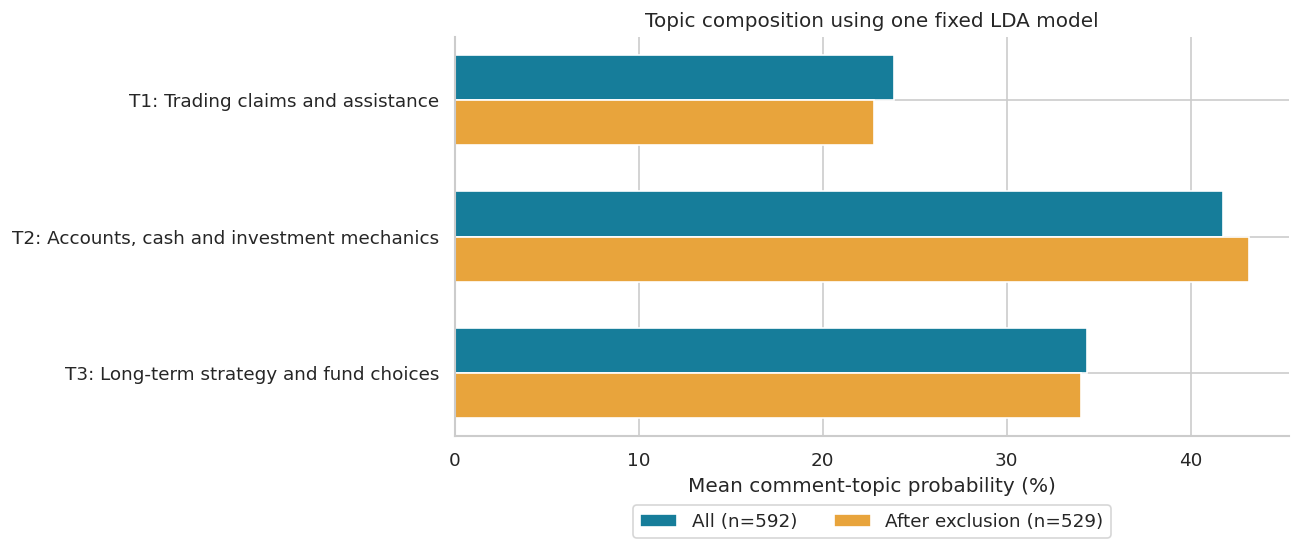


Refitted retained-corpus topics (R IDs belong to this new fit):
R1: trading, bro, profit, stock, portfolio, help, tax, investment, trade, pie
  Invest and trade Crypto, Forex, Stocks and Bonds yourself without sending money to no one with the best investment modules and advice of Elianna_Grant_Trades on Instagram today and make daily Profits. She's legit, I'm a benefactor, I trust and I recommend her.
  why not vanguard and instead trading 212? I have the app. I'm currently using etoro for general investments, moneybox for lisa and vanguard for stocks and shares isa.
R2: isa, cash, much, invest, trading, stock, money, like, get, invested
  So if I want to move everything across to a stocks ISA account, I need to sell my shares first? I accidentally opened an invest account when I started instead of a stocks lol.
  wouldn't really call it a crash , maybe use the term "falling " crash would be like double digit % decline within 48 hours , unless you just using buzz words for algorithms


**Interpretation of the comparison.** Each row of theta contains the topic probabilities for one comment. These probabilities sum to one. The averages give every comment equal weight. A mean topic probability shows the average weight assigned to a topic. It does not count how many comments mention that topic. The fixed-model comparison uses the same fitted LDA model before and after exclusion. Its differences describe changes within this sample. The random-seed check shows how the results vary when the model starts from different random values. Coherence scores and topic alignment do not measure classification accuracy.

In [60]:
#@title Part 4D — Fixed-model topic comparison, refit and seed diagnostic
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import jensenshannon

labels = {j: f'Topic {j+1}' for j in range(K)}
# Describe topics by their actual keyword signatures rather than relying on topic order.
for j in range(K):
    words = {w for w,_ in lda.show_topic(j,topn=10)}
    if {'profit','thank'}.issubset(words):
        labels[j] = 'Trading claims and assistance'
    elif {'isa','cash'}.issubset(words):
        labels[j] = 'Accounts, cash and investment mechanics'
    elif {'year','fund'}.issubset(words):
        labels[j] = 'Long-term strategy and fund choices'

keep_topic = (~topic_df.suspected_promo).to_numpy()
assert keep_topic.any() and (~keep_topic).any()
topic_comparison = pd.DataFrame({
    'topic':[f'T{j+1}: {labels[j]}' for j in range(K)],
    'all_pct':theta.mean(axis=0)*100,
    'retained_pct':theta[keep_topic].mean(axis=0)*100,
    'flagged_pct':theta[~keep_topic].mean(axis=0)*100})
topic_comparison['change_pp'] = topic_comparison.retained_pct-topic_comparison.all_pct
print(f'Topic-analysis denominator: all n={len(topic_df)}, retained n={keep_topic.sum()}, flagged n={(~keep_topic).sum()}')
print(topic_comparison.round(3).to_string(index=False))
topic_comparison.to_csv(OUT/'topic_share_fixed_model.csv',index=False)

fig,ax = plt.subplots(figsize=(11,4.8))
y=np.arange(K); h=.33
ax.barh(y-h/2,topic_comparison.all_pct,h,label=f'All (n={len(topic_df)})',color='#167D9A')
ax.barh(y+h/2,topic_comparison.retained_pct,h,label=f'After exclusion (n={keep_topic.sum()})',color='#E8A43C')
ax.set_yticks(y,[f'T{j+1}: {labels[j]}' for j in range(K)])
ax.set_xlabel('Mean comment-topic probability (%)'); ax.invert_yaxis()
ax.set_title('Topic composition using one fixed LDA model')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2)
fig.tight_layout(); fig.savefig(OUT/'04_topic_comparison.png',bbox_inches='tight'); plt.show()

retained_corpus = [bow for bow,keep in zip(corpus,keep_topic) if keep]
lda_retained = fit_lda(retained_corpus,K)
lda_retained.random_state=np.random.RandomState(SEED)
retained_theta=np.array([[p for _,p in lda_retained.get_document_topics(bow,minimum_probability=0)] for bow in retained_corpus])
refit_examples=[]
print('\nRefitted retained-corpus topics (R IDs belong to this new fit):')
for j in range(K):
    keywords=', '.join(w for w,_ in lda_retained.show_topic(j,topn=10))
    print(f'R{j+1}: {keywords}')
    examples=topic_df.loc[keep_topic].assign(refit_probability=retained_theta[:,j]).sort_values('refit_probability',ascending=False).drop_duplicates('raw_text').head(2)
    for _,r in examples.iterrows():
        print(' ',r.display_text)
        refit_examples.append({'refit_topic':j+1,'keywords':keywords,'comment_id':r.comment_id,'display_text':r.display_text})
pd.DataFrame(refit_examples).to_csv(OUT/'lda_refit_examples.csv',index=False)

def topic_alignment(model_a,model_b):
    a,b=model_a.get_topics(),model_b.get_topics()
    distances=np.array([[jensenshannon(x,y) for y in b] for x in a])
    rows,cols=linear_sum_assignment(distances)
    records=[]
    for r,c in zip(rows,cols):
        wa={w for w,_ in model_a.show_topic(int(r),topn=10)}
        wb={w for w,_ in model_b.show_topic(int(c),topn=10)}
        records.append({'baseline_topic':int(r)+1,'matched_topic':int(c)+1,'JS_distance':float(distances[r,c]),'top10_Jaccard':len(wa&wb)/len(wa|wb)})
    return pd.DataFrame(records)

lda_other_seed=fit_lda(corpus,K,seed=7)
seed_alignment=topic_alignment(lda,lda_other_seed)
refit_alignment=topic_alignment(lda,lda_retained)
print('\nAlternative seed: lower JS distance and higher Jaccard indicate greater similarity.')
print(seed_alignment.round(3).to_string(index=False))
print('\nRetained-model alignment: approximate matches, not proof of topic identity.')
print(refit_alignment.round(3).to_string(index=False))
seed_alignment.to_csv(OUT/'lda_seed_stability.csv',index=False)
refit_alignment.to_csv(OUT/'lda_refit_alignment.csv',index=False)

joined=topic_df.assign(topic=topic_df.dominant_topic.map(lambda j:f'T{j+1}'))
topic_sentiment=joined.groupby('topic').agg(n=('comment_id','size'),mean_polarity=('polarity','mean'),flagged_pct=('suspected_promo',lambda x:x.mean()*100))
print('\nSentiment by dominant-topic group (mixed membership simplified):')
print(topic_sentiment.round(3).to_string())
topic_sentiment.to_csv(OUT/'sentiment_by_topic.csv')
display(Markdown('**Interpretation of the comparison.** Each row of theta contains the topic probabilities for one comment. These probabilities sum to one. The averages give every comment equal weight. A mean topic probability shows the average weight assigned to a topic. It does not count how many comments mention that topic. The fixed-model comparison uses the same fitted LDA model before and after exclusion. Its differences describe changes within this sample. The random-seed check shows how the results vary when the model starts from different random values. Coherence scores and topic alignment do not measure classification accuracy.'))


## Part 4E — Brief reflection

- **Sentiment and topics:** The patterns partly align. Trading and long-term investment groups have higher mean polarity than the account-related group.

- **Tone of discussion:** The sample is mainly positive or neutral, with some critical comments. These results do not establish clear polarization.

- **Practical insights:** Policymakers and NGOs could focus financial-literacy work on account choices and investment risks. Moderators could use the promotion flags to guide human review while preserving questions and criticism.



## Part 5 — Interpretation and limitations

### RQ1: What do users discuss?

The baseline LDA model suggests three possible themes. These themes overlap. The interpretation draws on both topic keywords and representative comments.

1. **Trading claims and assistance.** Words such as **trading**, **profit**, **thank**, **investment** and **help** connect several types of discussion. Some comments describe investment profits. Others ask for help or discuss trading platforms. This theme includes promotional wording, but it also contains ordinary investment discussion.

2. **Accounts, cash and investment mechanics.** Words such as **ISA**, **cash**, **account**, **interest** and **stocks** point to practical questions about managing money. Users discuss platforms, account types and returns. Some comments also mention market losses.

3. **Long-term strategy and fund choices.** Words such as **year**, **investing**, **fund** and **time** suggest discussion of investment periods and portfolio choices. Representative comments mention buy-and-hold strategies, compounding and index funds. Some users question the creator’s performance, so this theme includes both supportive and critical views.

The word analysis supports these interpretations. **Year** and **ISA** remain prominent after suspected promotions are excluded. **Profit**, **trading** and **grateful** lose weight. These patterns suggest that financial questions, peer advice and promotional messages appear together in the comment section. LDA provides an exploratory overview, but it does not capture every topic.

### RQ2: What sentiment do the comments express?

The results show substantial positive and neutral language. Negative classifications are less common. These scores do not directly measure audience trust or satisfaction.

A question may receive a positive score because it contains a favourable word. A warning about financial losses may receive a neutral score if the tool misses its meaning. The subjectivity score also reflects language patterns. It does not measure whether a comment is truthful or reliable.

### RQ3: What changes when suspected promotions are excluded?

The computed summary shows how sentiment and topic estimates change after exclusion. These changes describe the selected sample. They do not establish that promotional comments caused the differences. The results also cannot represent the wider TikTok population or prove that a flagged comment is fraudulent.

### Critical reflection

- **Promotion flags:** The rule can miss promotions without an @mention. One representative comment advertises an Instagram trader without this marker. Another “side hustle” message lacks the terms required by the rule. Some unflagged comments may therefore still contain promotional content. The audit file’s human-review fields remain blank, so the analysis has no independent human validation or inter-coder agreement estimate.

- **Sample and language:** The data come from a provider sample with an unknown sampling process. The dataset does not contain every comment on each video. Language detection also excludes some short English comments, such as “Why not vanguard?” The confidence-threshold comparison addresses only part of this problem.

- **Model limitations:** Short comments give the models limited context. Repeated wording and missing video or reply context create further uncertainty. The LDA results also vary across random seeds. These limitations make the topic labels provisional.

- **Dependence between comments:** Several comments may come from the same video or user. The comments cannot therefore be treated as independent random observations. The reported percentages are descriptive, and the analysis does not include statistical significance tests.

- **Overlap between rules and sentiment:** The promotion rules partly rely on favourable testimonial wording. This may help explain why flagged comments appear more positive. The strict rule produces a much smaller sentiment change. The interpretation should therefore acknowledge that the results depend on how promotions are defined.

**Practical implication:** Platform moderators and financial-literacy educators should distinguish investment questions and criticism from promotional messages. A single positive-sentiment figure can hide these differences. Human review, better language screening, more context and broader sampling could improve the analysis. The exploratory promotion rule alone does not justify automatic comment deletion or enforcement.



In [61]:
#@title Computed answers, reconciliation checks and export
largest_change=topic_comparison.iloc[topic_comparison.change_pp.abs().argmax()]
strict_shift=sensitivity.loc[sensitivity.neutral_band.eq(.05)&sensitivity.exclusion_rule.eq('promo_strict'),'change_pp'].iloc[0]
summary_md=f"""### Results from this run
- **Sample:** {len(case)} account comments; {len(analysis)} eligible English comments; {len(topic_df)} nonempty LDA documents.
- **Sentiment, all eligible comments:** {sentiment_results.loc[0,'Positive_pct']:.1f}% positive, {sentiment_results.loc[0,'Neutral_pct']:.1f}% neutral and {sentiment_results.loc[0,'Negative_pct']:.1f}% negative.
- **Base-rule exclusion:** {len(flagged)} comments ({100*len(flagged)/len(analysis):.1f}% of eligible comments). Positive share changes from {sentiment_results.loc[0,'Positive_pct']:.1f}% to {sentiment_results.loc[1,'Positive_pct']:.1f}% ({positive_shift:+.1f} percentage points); mean polarity changes from {analysis.polarity.mean():.3f} to {retained.polarity.mean():.3f}.
- **Rule sensitivity:** the strict rule gives a positive-share change of only {strict_shift:+.2f} percentage points. The magnitude depends on which content is excluded.
- **Topic comparison:** the largest fixed-model shift is {largest_change['topic']}: {largest_change.all_pct:.1f}% to {largest_change.retained_pct:.1f}% ({largest_change.change_pp:+.1f} percentage points). These percentages are average topic probabilities.
- **Model selection:** K={K}; c_v={model_diagnostics.loc[model_diagnostics.k.eq(K),'coherence_cv'].iloc[0]:.3f}. Mean matched top-10-word Jaccard under a different seed is {seed_alignment.top10_Jaccard.mean():.3f}; topics should be treated as exploratory.
"""
display(Markdown(summary_md))
(OUT/'results_summary.md').write_text(summary_md,encoding='utf-8')

assert analysis.comment_id.is_unique
assert len(analysis)==len(retained)+len(flagged)
assert analysis.polarity.between(-1,1).all()
assert analysis.subjectivity.between(0,1).all()
assert np.allclose(sentiment_results[[s+'_pct' for s in ORDER]].sum(axis=1),100)
assert np.allclose(topic_comparison[['all_pct','retained_pct','flagged_pct']].sum(),100,atol=.001)
assert len(corpus)==len(topic_df)==theta.shape[0]
assert np.isfinite(theta).all()
assert len(topic_df)<=len(analysis)

export_columns=['comment_id','post_id','user_label','display_text','date_created','num_likes','num_replies','language','language_confidence','token_count','suspected_promo','promo_strict','promo_broad','flag_features','polarity','subjectivity','sentiment']
analysis[export_columns].to_csv(OUT/'comment_analysis.csv',index=False)
topic_df[['comment_id','dominant_topic','topic_probability']+[f'topic_{j+1}_probability' for j in range(K)]].to_csv(OUT/'comment_topic_probabilities.csv',index=False)
(OUT/'requirements_observed.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versions.items())+'\n')
flow_final=pd.DataFrame({'stage':['Source','Selected account','Eligible English','After base-rule exclusion','LDA baseline','LDA after exclusion'],
                         'n':[len(raw),len(case),len(analysis),len(retained),len(topic_df),int(keep_topic.sum())]})
flow_final.to_csv(OUT/'sample_flow_final.csv',index=False)
print('All reconciliation checks passed.')
print('Final sample flow:\n'+flow_final.to_string(index=False))
print('Figures and CSV tables are saved to:',OUT)


### Results from this run
- **Sample:** 799 account comments; 678 eligible English comments; 592 nonempty LDA documents.
- **Sentiment, all eligible comments:** 45.6% positive, 44.8% neutral and 9.6% negative.
- **Base-rule exclusion:** 63 comments (9.3% of eligible comments). Positive share changes from 45.6% to 42.3% (-3.3 percentage points); mean polarity changes from 0.155 to 0.135.
- **Rule sensitivity:** the strict rule gives a positive-share change of only -0.38 percentage points. The magnitude depends on which content is excluded.
- **Topic comparison:** the largest fixed-model shift is T2: Accounts, cash and investment mechanics: 41.8% to 43.2% (+1.4 percentage points). These percentages are average topic probabilities.
- **Model selection:** K=3; c_v=0.367. Mean matched top-10-word Jaccard under a different seed is 0.313; topics should be treated as exploratory.


All reconciliation checks passed.
Final sample flow:
                    stage    n
                   Source 1000
         Selected account  799
         Eligible English  678
After base-rule exclusion  615
             LDA baseline  592
      LDA after exclusion  529
Figures and CSV tables are saved to: /content/nmc5342_outputs


### Method references
- [Dataset repository](https://github.com/luminati-io/Social-media-dataset-samples)
- [TextBlob quickstart: sentiment](https://textblob.readthedocs.io/en/dev/quickstart.html#sentiment-analysis)
- [Gensim LdaModel](https://radimrehurek.com/gensim/models/ldamodel.html)
- [Gensim CoherenceModel](https://radimrehurek.com/gensim/models/coherencemodel.html)
- [scikit-learn TF–IDF documentation](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting)
